# Introduction

## Dataset

The dataset contains transactions made by credit cards in September 2013 by European cardholders.
This dataset presents transactions that occurred in two days, where we have 492 frauds out of 284,807 transactions. The dataset is highly unbalanced, the positive class (frauds) account for 0.172% of all transactions.

It contains only numerical input variables which are the result of a PCA transformation. Unfortunately, due to confidentiality issues, we cannot provide the original features and more background information about the data. Features V1, V2, … V28 are the principal components obtained with PCA, the only features which have not been transformed with PCA are 'Time' and 'Amount'. Feature 'Time' contains the seconds elapsed between each transaction and the first transaction in the dataset. The feature 'Amount' is the transaction Amount, this feature can be used for example-dependant cost-sensitive learning. Feature 'Class' is the response variable and it takes value 1 in case of fraud and 0 otherwise.

In [16]:

import kagglehub
from kagglehub import KaggleDatasetAdapter
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np


file_path = "creditcard.csv"


df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "mlg-ulb/creditcardfraud",
  file_path,
)

print("First 5 records:", df.head())

C:\Users\egrac\AppData\Local\Temp\ipykernel_10272\3314394336.py:11: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


First 5 records:    Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26    

In [6]:
counts = df['Class'].value_counts()
print(counts)

Class
0    284315
1       492
Name: count, dtype: int64


The dataset contains 492 fraudulent transactions and 284,315 normal ones, making it highly imbalanced.

In [8]:
stats = df.groupby('Class').describe()
print(stats.T)

Class                     0             1
Time   count  284315.000000    492.000000
       mean    94838.202258  80746.806911
       std     47484.015786  47835.365138
       min         0.000000    406.000000
       25%     54230.000000  41241.500000
...                     ...           ...
Amount min         0.000000      0.000000
       25%         5.650000      1.000000
       50%        22.000000      9.250000
       75%        77.050000    105.890000
       max     25691.160000   2125.870000

[240 rows x 2 columns]


## Interpretable featrues analysis

C:\Users\egrac\AppData\Local\Temp\ipykernel_10272\145897116.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='Class', y='Amount_log', palette='Set2')


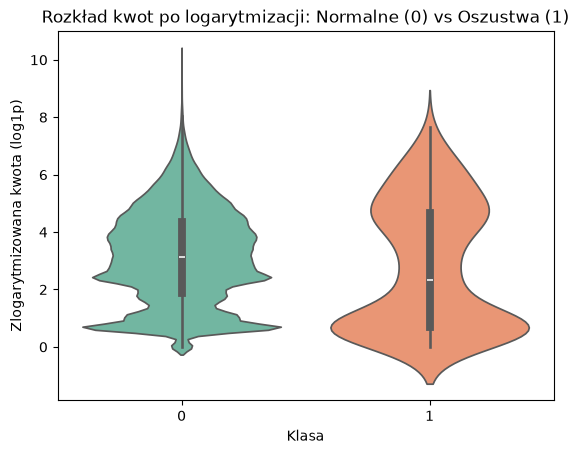

In [17]:
df['Amount_log'] = np.log1p(df['Amount'])

sns.violinplot(data=df, x='Class', y='Amount_log', palette='Set2')

plt.title("Rozkład kwot po logarytmizacji: Normalne (0) vs Oszustwa (1)")
plt.xlabel("Klasa")
plt.ylabel("Zlogarytmizowana kwota (log1p)")
plt.show()

For fraudulent transactions, we can observe a much higher frequency of both extremely low and relatively high values compared to non-fraudulent transactions.

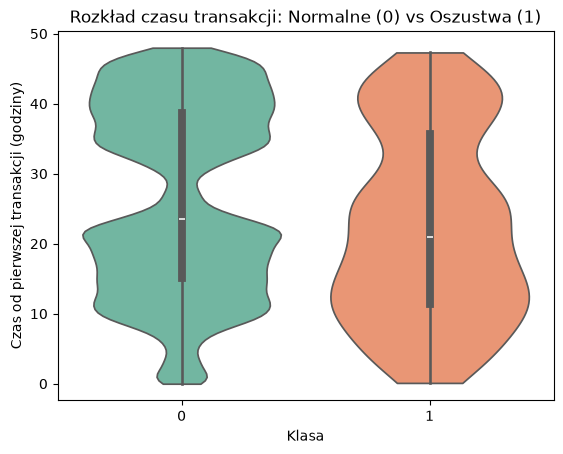

In [20]:


# 1. Zamiana sekund na godziny
df['Time_hours'] = df['Time'] / 3600

# 2. Rysowanie wykresu
# Dodajemy hue='Class' i legend=False, aby pozbyć się błędu z 'palette'
sns.violinplot(data=df, x='Class', y='Time_hours', hue='Class', palette='Set2', legend=False, cut=0)

# 3. Zaktualizowane tytuły i etykiety
plt.title("Rozkład czasu transakcji: Normalne (0) vs Oszustwa (1)")
plt.xlabel("Klasa")
plt.ylabel("Czas od pierwszej transakcji (godziny)")

plt.show()

As we can see, fraudulent transactions tend to be more evenly distributed across the two days, especially during night hours. In the early hours, there are proportionally more fraudulent transactions compared to non-fraudulent ones.